# Partie A — Cadrer, découper, explorer — Battery RUL

Ce notebook applique, question par question, la démarche du cours (cadrer → réserver le test → explorer le train → préparer les données → baseline) au dataset du projet : [Battery Remaining Useful Life (RUL)](https://www.kaggle.com/datasets/razanihababdellatif/battery-remaining-useful-life-rul-dataset) (Kaggle, CC0, synthétique).

Pour chaque question, deux cas :
- **Applicable** : on répond avec le raisonnement standard, adapté au contexte.
- **Non applicable** : on explique pourquoi la question ne se pose pas pour ce problème de régression, et quelle action on fait à la place.

**Question du projet** : à partir des mesures du cycle courant et de l'historique d'une batterie, prédire le nombre de cycles de charge/décharge restants avant sa fin de vie (`remaining_useful_cycles`), pour décider du moment de son remplacement préventif. **Type de problème** : régression. **Unité indépendante** : la batterie (`battery_id`).

## 0. Environnement

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import GroupKFold

SEED = 42
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.12 | pandas 2.3.3 | scikit-learn 1.9.1


## 1. Charger et décrire les données

Deux fichiers, à joindre sur `battery_id` : `battery_metadata.csv` (une ligne par batterie, caractéristiques fixes) et `battery_observations.csv` (une ligne par cycle de charge/décharge).

**Dictionnaire des variables (principales)**

| Variable | Signification | Source |
| --- | --- | --- |
| `battery_id` | identifiant de la batterie (clé de jointure) | les deux fichiers |
| `chemistry`, `manufacturer`, `climate_zone`, `usage_strategy` | caractéristiques fixes de la batterie | `battery_metadata.csv` |
| `nominal_capacity_kwh` | capacité nominale | `battery_metadata.csv` |
| `dataset_split` | split Train/Validation/Test fourni par le dataset | `battery_metadata.csv` |
| `cycle_index`, `battery_age_days` | position du cycle dans la vie de la batterie | `battery_observations.csv` |
| `state_of_health_pct` | état de santé (100 % = neuve) | `battery_observations.csv` |
| `internal_resistance_mOhm`, `pack_temp_c`, `ambient_temp_c` | mesures physiques du cycle | `battery_observations.csv` |
| `charge/discharge_current_a`, `*_c_rate`, `*_duration_min`, `depth_of_discharge_pct`, `soc_start/end_pct` | conditions d'usage du cycle | `battery_observations.csv` |
| `eol_reached` | la batterie a-t-elle terminé sa vie dans la fenêtre observée (flag par batterie) | `battery_observations.csv` |
| `remaining_useful_cycles` | **cible** : cycles restants avant fin de vie | `battery_observations.csv` |
| `remaining_useful_efc`, `degradation_status` | cibles alternatives non retenues ici | `battery_observations.csv` |

**Q1.** Combien d'observations et de variables explicatives contient le jeu ? Quelle est la cible et comment est-elle codée ? Pandas signale-t-il des valeurs manquantes ?

In [2]:
meta = pd.read_csv("battery_metadata.csv")
obs = pd.read_csv("battery_observations.csv")

print("battery_metadata.csv     :", meta.shape)
print("battery_observations.csv :", obs.shape)
display(meta.head())
display(obs.info())

battery_metadata.csv     : (200, 7)
battery_observations.csv : (172779, 31)


,battery_id,chemistry,manufacturer,climate_zone,nominal_capacity_kwh,usage_strategy,dataset_split
0,BAT-00001,LFP,CellCorp,Temperate,86.72,Balanced,Train
1,BAT-00002,NMC,Electronica,Nordic,61.79,Conservative,Validation
2,BAT-00003,LFP,Electronica,Desert,82.86,Aggressive,Test
3,BAT-00004,NMC,Electronica,Nordic,67.31,Conservative,Train
4,BAT-00005,LFP,CellCorp,Nordic,81.44,Conservative,Train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172779 entries, 0 to 172778
Data columns (total 31 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   battery_id                       172779 non-null  object 
 1   timestamp                        172779 non-null  object 
 2   cycle_index                      172779 non-null  int64  
 3   battery_age_days                 172779 non-null  float64
 4   time_since_previous_cycle_hours  172779 non-null  float64
 5   equivalent_full_cycles           172779 non-null  float64
 6   soc_start_pct                    172779 non-null  float64
 7   soc_end_pct                      172779 non-null  float64
 8   depth_of_discharge_pct           172779 non-null  float64
 9   high_soc_exposure_fraction       172779 non-null  float64
 10  low_soc_exposure_fraction        172779 non-null  float64
 11  charge_c_rate                    172779 non-null  float64
 12  di

None

**Réponse Q1.** 172 779 observations (cycles) sur 31 colonnes dans `battery_observations.csv`, pour 200 batteries (7 colonnes) dans `battery_metadata.csv` ; une fois joints, ≈ 36 variables, dont ≈ 30 explicatives (hors identifiant, split, cible et variables à exclure). La cible est `remaining_useful_cycles`, un entier/flottant (nombre de cycles restants), pas une classe. Pandas signale des valeurs manquantes : `pack_temp_c` (valeurs physiques), et `remaining_useful_cycles`/`remaining_useful_efc` sur les cycles de batteries censurées (`eol_reached = False`).

## 2. Cadrer la question

**Q2.** Rédigez la question en une phrase en précisant : ce que l'on prédit, pour qui, à partir de quelles informations, et pour quelle décision.

> **Réponse Q2.** À partir des mesures du cycle courant et de l'historique d'une batterie (état de santé, température, résistance interne, profondeur de décharge...), on prédit le nombre de cycles de charge/décharge restants avant sa fin de vie (`remaining_useful_cycles`), pour décider du moment de son remplacement préventif.

**Q3.** Quelle est l'erreur la plus coûteuse : sur-estimer ou sous-estimer le RUL ? Justifiez, puis dites qui devrait valider ce choix.

> **Réponse Q3.** Sur-estimer le RUL est le plus coûteux : la batterie risque de tomber en panne avant le remplacement planifié (arrêt non prévu, voire risque de sécurité). Sous-estimer entraîne juste un remplacement anticipé par précaution (coût économique, pas de risque opérationnel). Ce choix devrait être validé par un ingénieur maintenance/fiabilité, qui connaît le vrai coût d'une panne non planifiée pour l'application visée.

**Q4.** Quelle est l'unité indépendante ici ? Peut-on vérifier qu'une même batterie (ou un même cycle) n'apparaît pas plusieurs fois ?

In [3]:
print("Lignes strictement dupliquées (battery_observations) :", obs.duplicated().sum())
print("Paires (battery_id, cycle_index) dupliquées            :", obs.duplicated(subset=["battery_id", "cycle_index"]).sum())

Lignes strictement dupliquées (battery_observations) : 0
Paires (battery_id, cycle_index) dupliquées            : 0


**Réponse Q4.** L'unité indépendante est la batterie (`battery_id`) — les cycles d'une même batterie sont corrélés (dégradation progressive), donc ce n'est pas le cycle. On vérifie qu'aucun cycle n'est enregistré deux fois pour la même batterie : 0 ligne strictement dupliquée, 0 paire `(battery_id, cycle_index)` dupliquée.

**Q5.** Quelle(s) métrique(s) proposez-vous en première approche ? Pourquoi pas l'exactitude seule ?

> **Réponse Q5.** La MAE (erreur absolue moyenne, en cycles), éventuellement complétée par la RMSE. **Non applicable telle quelle** : l'exactitude, le rappel, la précision n'existent qu'en classification (il faut des classes à compter correctement/incorrectement) ; ici la cible est continue, donc on compare directement des valeurs prédites à des valeurs réelles. La MAE a été choisie plutôt qu'une métrique basée sur la médiane car elle ne masque pas les grosses erreurs — or ce sont justement les grosses sur-estimations du RUL (Q3) qu'on veut détecter.

## 3. Découper et fermer le test

Le dataset fournit déjà un découpage par batterie (`dataset_split`). On le reprend tel quel, et on ferme le test dès maintenant.

In [4]:
train_ids = meta.loc[meta["dataset_split"] == "Train", "battery_id"]
val_ids = meta.loc[meta["dataset_split"] == "Validation", "battery_id"]
test_ids = meta.loc[meta["dataset_split"] == "Test", "battery_id"]

obs_train = obs[obs["battery_id"].isin(train_ids)].copy()
obs_val = obs[obs["battery_id"].isin(val_ids)].copy()
obs_test = obs[obs["battery_id"].isin(test_ids)].copy()

print("train :", obs_train.shape[0], "lignes,", train_ids.nunique(), "batteries")
print("val   :", obs_val.shape[0], "lignes,", val_ids.nunique(), "batteries")
print("test  :", obs_test.shape[0], "lignes,", test_ids.nunique(), "batteries (fermé jusqu'au bout)")

train : 122255 lignes, 140 batteries
val   : 24986 lignes, 30 batteries
test  : 25538 lignes, 30 batteries (fermé jusqu'au bout)


**Q6.** Que garantirait une stratification sur la cible (comme `stratify=y` en classification) ? Que risque-t-on sans elle ?

> **Réponse Q6 — non applicable telle quelle, action différente.** La stratification sert à préserver la proportion de chaque **classe** dans train/test ; ici la cible est continue (régression), donc il n'y a pas de classes à stratifier (on pourrait stratifier sur une version discrétisée du RUL, mais ce n'est pas fait ici). Le vrai risque à gérer est différent et plus important : les lignes ne sont pas indépendantes (cycles d'une même batterie corrélés). **Action à la place** : découpage **par groupe** (la batterie), pas aléatoire ligne par ligne — exactement ce qui est fait ci-dessus via `dataset_split`. Sans cela, des cycles très proches d'une même batterie se retrouveraient dans le train et dans le test, ce qui ferait fuiter de l'information et donnerait une évaluation trop optimiste.

> **Règle pour la suite :** `obs_test` n'est plus utilisé avant l'évaluation finale. Toute l'exploration porte sur `obs_train`.

## 4. Explorer le train
### 4.1 Statistiques descriptives

On joint d'abord `obs_train` aux caractéristiques fixes de la batterie.

In [5]:
train = obs_train.merge(meta.drop(columns="dataset_split"), on="battery_id", how="left")
train.select_dtypes("number").describe().T

,count,mean,std,min,25%,50%,75%,max
cycle_index,122255.0,531.313165,374.956038,1.000000,221.000,456.00,791.000,1500.000000
battery_age_days,122255.0,911.312704,658.880806,0.500000,371.400,764.00,1361.400,2688.200000
time_since_previous_cycle_hours,122255.0,41.003216,17.406778,12.000000,25.900,40.20,56.100,72.000000
equivalent_full_cycles,122255.0,204.981132,132.684341,0.070000,92.690,187.77,308.005,595.460000
soc_start_pct,122255.0,77.759414,10.896439,33.400000,70.200,78.30,86.000,100.000000
soc_end_pct,122255.0,36.931850,15.327878,5.000000,25.700,36.60,47.500,92.800000
depth_of_discharge_pct,122255.0,40.827314,15.517194,5.000000,29.400,39.60,51.300,93.200000
high_soc_exposure_fraction,122255.0,0.082672,0.140126,0.000000,0.000,0.00,0.133,1.000000
low_soc_exposure_fraction,122255.0,0.015231,0.045321,0.000000,0.000,0.00,0.000,0.514000
charge_c_rate,122255.0,0.616126,0.378641,0.110000,0.370,0.54,0.720,2.500000


**Q7.** Quelles valeurs minimales vous surprennent ? Lesquelles sont physiquement possibles ?

In [6]:
num = train.select_dtypes("number")
zeros = (num == 0).sum()
zeros[zeros > 0].sort_values(ascending=False)

cooling_active                113295
low_soc_exposure_fraction     104238
high_soc_exposure_fraction     68101
cumulative_high_temp_hours     65679
remaining_useful_cycles          118
remaining_useful_efc             118
ambient_temp_c                    71
pack_temp_c                       70
dtype: int64

**Réponse Q7 — non applicable, action différente.** Dans d'autres jeux de données, des zéros remplacent parfois des valeurs manquantes de façon déguisée (une mesure physique à 0 qui n'a pas de sens). Ici, **aucun zéro n'est suspect** : `cooling_active` est un indicateur 0/1 (0 = refroidissement inactif, normal), `high/low_soc_exposure_fraction` et `cumulative_high_temp_hours` valent légitimement 0 quand la batterie n'a jamais été exposée à ces conditions, `ambient_temp_c`/`pack_temp_c` à 0 sont des températures réelles (0 °C), et `remaining_useful_cycles`/`remaining_useful_efc` à 0 signifient simplement qu'une batterie est tout juste arrivée en fin de vie — une vraie valeur, pas une donnée manquante. **Action à la place** : le vrai mécanisme de valeur manquante ici est le NaN explicite (`pack_temp_c`, et la cible sur les cycles censurés), déjà identifié et quantifié ci-dessous — pas besoin de chercher des zéros déguisés.

### 4.2 Les vraies valeurs manquantes (remplace "les zéros suspects", non pertinent ici)

In [7]:
manquants = train.isna().sum()
manquants = manquants[manquants > 0]
pd.DataFrame({"nombre de NaN": manquants, "% du train": (manquants / len(train) * 100).round(2)})

,nombre de NaN,% du train
pack_temp_c,1242,1.02
remaining_useful_cycles,32802,26.83
remaining_useful_efc,32802,26.83


**Q8.** Que se passerait-il si l'on supprimait toutes les lignes avec une valeur manquante ? Quelle variable pose le plus de problème ?

> **Réponse Q8.** `pack_temp_c` n'a que ≈ 1,0 % de valeurs manquantes (1242/122255) : les supprimer ferait perdre très peu de données, une imputation simple (médiane) suffit. La cible (`remaining_useful_cycles`) manque, elle, sur ≈ 26,8 % des lignes (32 802/122 255) — bien plus problématique, car ce ne sont pas des lignes "à nettoyer" mais des cycles **censurés** (batteries encore en service) : on ne peut pas les imputer (on ne connaît pas leur vrai RUL), on les exclut donc de l'apprentissage/évaluation supervisée plutôt que de les supprimer "au hasard". La variable qui pose le plus de problème est donc la cible elle-même, via la censure — pas une variable explicative.

---
### 4.3 Équilibre des classes — non applicable, action différente

**Q9.** Quelle exactitude obtiendrait un « modèle » qui répond toujours une même classe ? Quel serait son rappel ?

> **Réponse Q9 — non applicable, action différente.** Il n'y a pas de classes ici (régression), donc ni exactitude ni rappel. **Action à la place** : on regarde la distribution de la cible, et on calcule l'erreur d'un modèle naïf qui prédit toujours la même valeur (la médiane du train) — l'équivalent du "modèle qui répond toujours la même chose".

In [8]:
train_labeled = train[train["remaining_useful_cycles"].notna()].copy()

median_rul = train_labeled["remaining_useful_cycles"].median()
mae_naif = (train_labeled["remaining_useful_cycles"] - median_rul).abs().mean()

print("Lignes exploitables (label connu) :", train_labeled.shape[0])
print("Médiane du RUL (train)            :", median_rul)
print("MAE d'un modèle qui prédit toujours la médiane :", round(mae_naif, 2))

Lignes exploitables (label connu) : 89453
Médiane du RUL (train)            : 390.0
MAE d'un modèle qui prédit toujours la médiane : 257.83


### 4.4 Distributions

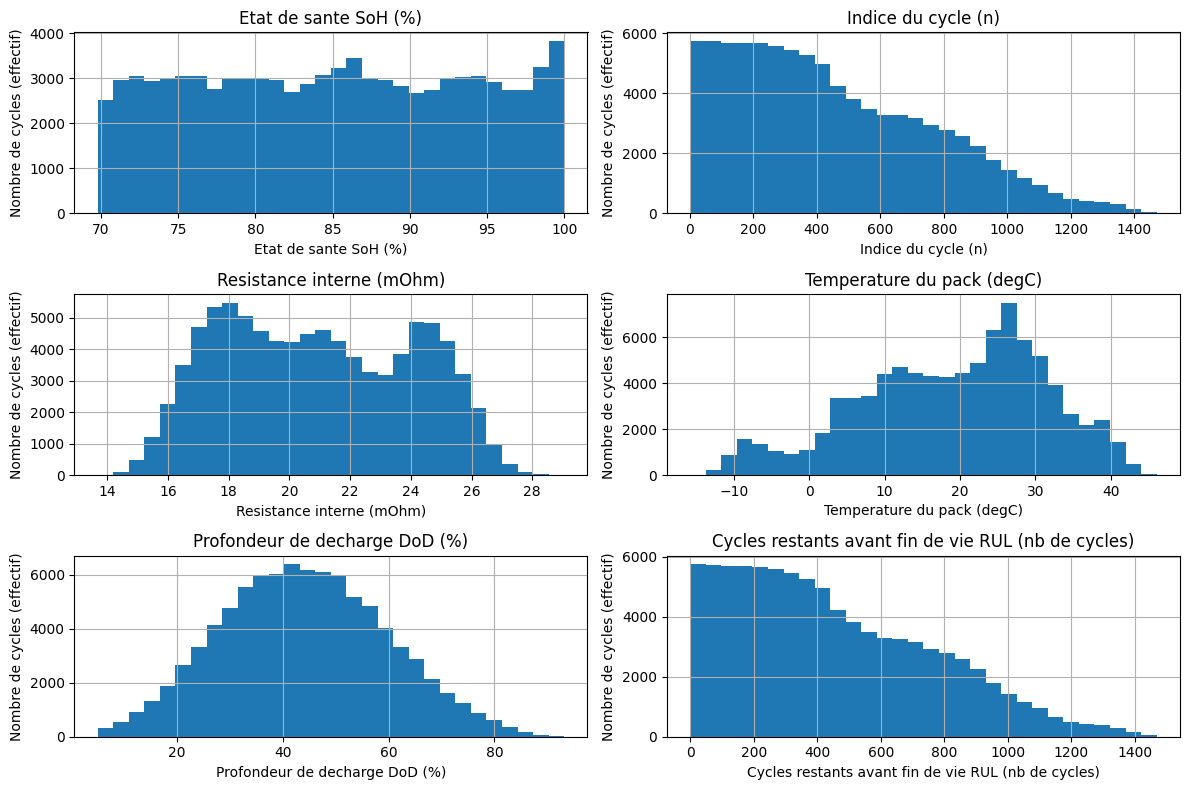

In [9]:
cols_a_tracer = ["state_of_health_pct", "cycle_index", "internal_resistance_mOhm",
                 "pack_temp_c", "depth_of_discharge_pct", "remaining_useful_cycles"]
labels_axes = {
    "state_of_health_pct": "Etat de sante SoH (%)",
    "cycle_index": "Indice du cycle (n)",
    "internal_resistance_mOhm": "Resistance interne (mOhm)",
    "pack_temp_c": "Temperature du pack (degC)",
    "depth_of_discharge_pct": "Profondeur de decharge DoD (%)",
    "remaining_useful_cycles": "Cycles restants avant fin de vie RUL (nb de cycles)",
}
axes = train_labeled[cols_a_tracer].hist(bins=30, figsize=(12, 8))
for ax, col in zip(axes.flatten(), cols_a_tracer):
    ax.set_title(labels_axes[col])
    ax.set_xlabel(labels_axes[col])
    ax.set_ylabel("Nombre de cycles (effectif)")
plt.tight_layout()
plt.show()

**Q10.** Que remarquez-vous sur la forme des distributions ?

> **Réponse Q10.** `state_of_health_pct` est à peu près symétrique, centrée autour de 85 %. `cycle_index` est plutôt uniforme/étalée (on observe des batteries à tous les stades de leur vie). `internal_resistance_mOhm` et `depth_of_discharge_pct` sont légèrement asymétriques. `remaining_useful_cycles` est **asymétrique à droite** (beaucoup de cycles encore loin de la fin de vie, moins proches de 0) — cohérent avec la Q9 (médiane 390 < moyenne 450).

### 4.5 Comparaison avec la cible — adapté (nuages de points au lieu de boxplots par classe)

On compare parfois une variable continue entre deux **classes** de la cible avec des boxplots. **Non applicable telle quelle** : ici la cible elle-même est continue, pas de classes à comparer. **Action à la place** : un nuage de points (scatter) de chaque variable contre `remaining_useful_cycles` (échantillon de 5000 points pour la lisibilité, vu les 89 453 lignes).

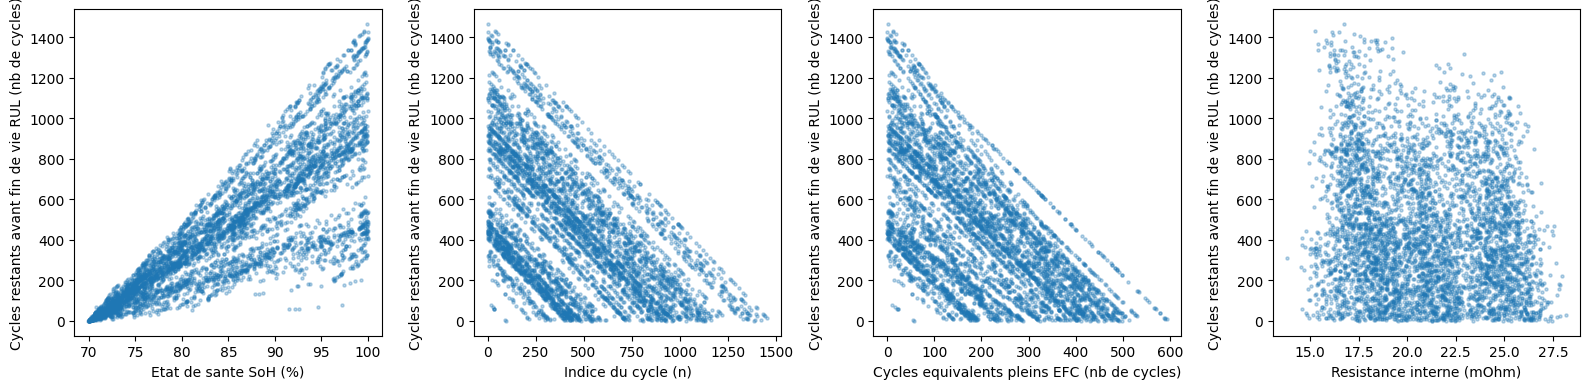

In [10]:
echantillon = train_labeled.sample(5000, random_state=SEED)
labels_axes = {
    "state_of_health_pct": "Etat de sante SoH (%)",
    "cycle_index": "Indice du cycle (n)",
    "equivalent_full_cycles": "Cycles equivalents pleins EFC (nb de cycles)",
    "internal_resistance_mOhm": "Resistance interne (mOhm)",
    "remaining_useful_cycles": "Cycles restants avant fin de vie RUL (nb de cycles)",
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["state_of_health_pct", "cycle_index", "equivalent_full_cycles", "internal_resistance_mOhm"]):
    ax.scatter(echantillon[col], echantillon["remaining_useful_cycles"], s=5, alpha=0.3)
    ax.set_xlabel(labels_axes[col])
    ax.set_ylabel(labels_axes["remaining_useful_cycles"])
plt.tight_layout()
plt.show()

**Q11.** Quelle variable semble la plus discriminante (liée à la cible) ? Une relation visible ici prouve-t-elle une causalité ?

> **Réponse Q11.** `state_of_health_pct` montre la relation la plus nette et la plus linéaire avec `remaining_useful_cycles` (plus le SoH est élevé, plus il reste de cycles). Non, une relation visible ne prouve pas une causalité directe : le SoH et le RUL sont tous les deux des **conséquences** du même processus physique de dégradation, pas l'un la cause de l'autre au sens strict — mais c'est bien suffisant pour en faire un bon prédicteur.

### 4.6 Corrélations

In [11]:
num_cols = train_labeled.select_dtypes("number").columns.drop(["remaining_useful_cycles", "remaining_useful_efc"])
corr_target = train_labeled[num_cols].corrwith(train_labeled["remaining_useful_cycles"]).sort_values(key=abs, ascending=False)
print(corr_target)

corr_features = train_labeled[num_cols].corr().abs()
paires = corr_features.where(~np.eye(len(corr_features), dtype=bool)).unstack().sort_values(ascending=False)
paires = paires[~paires.index.duplicated()]
print()
print("Paires de variables les plus corrélées entre elles :")
print(paires.head(5))

state_of_health_pct                0.814028
equivalent_full_cycles            -0.588202
cycle_index                       -0.521398
battery_age_days                  -0.505424
discharge_duration_min             0.193444
discharge_c_rate                  -0.187943
discharge_current_a               -0.187709
ambient_temp_c                     0.169600
cumulative_high_temp_hours        -0.166630
pack_temp_c                        0.166182
charge_duration_min                0.162824
internal_resistance_mOhm          -0.160331
depth_of_discharge_pct            -0.136646
soc_start_pct                     -0.126056
charge_current_a                  -0.113035
charge_c_rate                     -0.108213
energy_discharged_kwh              0.068534
high_soc_exposure_fraction        -0.060206
soc_end_pct                        0.054070
pack_voltage_charge_v             -0.052696
nominal_capacity_kwh              -0.036987
low_soc_exposure_fraction         -0.027156
pack_voltage_discharge_v        


Paires de variables les plus corrélées entre elles :
pack_temp_c               ambient_temp_c              0.999220
ambient_temp_c            pack_temp_c                 0.999220
pack_voltage_discharge_v  pack_voltage_mean_v         0.988742
pack_voltage_mean_v       pack_voltage_discharge_v    0.988742
                          pack_voltage_charge_v       0.988641
dtype: float64


**Q12.** Quelles variables sont les plus corrélées à la cible ? Quelles paires de variables sont corrélées entre elles ? Les valeurs manquantes peuvent-elles fausser ces corrélations ?

> **Réponse Q12.** `state_of_health_pct` (0.81) est de loin la plus corrélée au RUL, suivie de `equivalent_full_cycles` (-0.59), `cycle_index` (-0.52) et `battery_age_days` (-0.51). Entre elles, plusieurs variables sont redondantes : `pack_temp_c` et `ambient_temp_c` (corrélation ≈ 1.00, quasi doublon), les trois tensions `pack_voltage_*` (≈ 0.99 entre elles), `cycle_index` et `battery_age_days` (≈ 0.98), `charge_current_a` et `charge_c_rate` (≈ 0.98) — à garder en tête pour la modélisation (variables redondantes, pas forcément besoin de toutes les garder). Sur l'effet des valeurs manquantes : `pandas.corr()` ignore silencieusement les paires de lignes où l'une des deux variables est NaN (suppression par paire) ; avec seulement ≈ 1 % de NaN sur `pack_temp_c`, l'effet est négligeable ici.

## 5. Fiche de décisions de prétraitement

| Variable(s) | Constat | Décision | Justification |
| --- | --- | --- | --- |
| `remaining_useful_cycles` manquant (censure) | 26,8 % des cycles du train | exclure de l'apprentissage/évaluation supervisée | pas imputable (vrai RUL inconnu) ; biais de sélection à documenter |
| `pack_temp_c` | ≈ 1 % de NaN | imputer par la médiane du train | faible proportion, imputation simple suffisante |
| `eol_reached`, `remaining_useful_efc` | connus seulement a posteriori | exclure des variables explicatives | fuite (détaillée en partie B) |
| `chemistry`, `manufacturer`, `climate_zone`, `usage_strategy` | catégorielles sans ordre naturel | encodage one-hot | pas d'ordre logique entre catégories |
| `state_of_health_pct`, `pack_temp_c`, `ambient_temp_c`, etc. (variables numériques) | échelles très différentes | standardiser (StandardScaler) après imputation | nécessaire pour les modèles sensibles à l'échelle |
| Découpage train/validation/test | cycles non indépendants au sein d'une batterie | reprendre `dataset_split` (par batterie), pas de split aléatoire | éviter la fuite entre cycles d'une même batterie (Q4/Q6) |

## Points de contrôle
- [x] Q1 à Q12 traitées (adaptées quand nécessaire, avec action de remplacement sinon).
- [x] `obs_test` n'a été utilisé que pour vérifier ses dimensions.
- [x] La fiche de décisions est le point de départ de la partie B ci-dessous.

---
# Partie B — Préparer les données et construire une référence — Battery RUL

Le jeu de test (`obs_test`) reste fermé. Toutes les évaluations se font par validation croisée sur le train — mais **par groupe** (`GroupKFold` sur `battery_id`), pas un découpage ligne par ligne, puisque les lignes d'une même batterie ne sont pas indépendantes (Q4/Q6 de la partie A).

## 0. Reprise

In [12]:
# Reprise : chargement, jointure et split identiques à la partie A
FEATURES_NUM = [
    "cycle_index", "battery_age_days", "time_since_previous_cycle_hours",
    "equivalent_full_cycles", "soc_start_pct", "soc_end_pct", "depth_of_discharge_pct",
    "high_soc_exposure_fraction", "low_soc_exposure_fraction", "charge_c_rate", "discharge_c_rate",
    "charge_current_a", "discharge_current_a", "charge_duration_min", "discharge_duration_min",
    "energy_discharged_kwh", "ambient_temp_c", "pack_temp_c", "cumulative_high_temp_hours",
    "pack_voltage_mean_v", "pack_voltage_charge_v", "pack_voltage_discharge_v",
    "state_of_health_pct", "internal_resistance_mOhm", "nominal_capacity_kwh", "cooling_active",
]
FEATURES_CAT = ["chemistry", "manufacturer", "climate_zone", "usage_strategy"]

X = train_labeled[FEATURES_NUM + FEATURES_CAT]
y = train_labeled["remaining_useful_cycles"]
groups = train_labeled["battery_id"]
print("X :", X.shape, "| batteries distinctes :", groups.nunique())

X : (89453, 30) | batteries distinctes : 118


## 1. Traiter les valeurs manquantes réelles — adapté (pas de "zéros vers NaN" ici, cf. Q7 de la partie A)

On convertit parfois des zéros déguisés en NaN avant tout traitement. **Non applicable ici** : il n'y a pas de zéros déguisés (Q7). La seule vraie variable manquante est déjà codée en NaN (`pack_temp_c`) ; on l'impute directement dans le pipeline, et on ajoute un indicateur de son absence.

In [13]:
def ajouter_indicateur_temp(X):
    """Ajoute une colonne 0/1 « pack_temp_c manquant »."""
    X = X.copy()
    X["manquant_pack_temp_c"] = X["pack_temp_c"].isna().astype(int)
    return X

ajouter_indicateur_temp(X)["manquant_pack_temp_c"].mean().round(4)

np.float64(0.0101)

**Q1.** Le nombre obtenu correspond-il à celui de la partie A ? Pourquoi cette transformation ne crée-t-elle aucune fuite ?

> **Réponse Q1.** Oui : ≈ 1,0 % de `manquant_pack_temp_c` = 1, cohérent avec les 1242 NaN trouvés en Q8 de la partie A. Aucune fuite car `.isna()` ne calcule rien d'agrégé : chaque valeur est testée indépendamment des autres lignes.

**Q2.** Pourquoi crée-t-on un indicateur seulement pour `pack_temp_c`, et pas pour les autres variables numériques ?

> **Réponse Q2.** Parce que `pack_temp_c` est la seule variable explicative avec de vraies valeurs manquantes (Q8 de la partie A) — toutes les autres variables numériques du train sont complètes. Créer un indicateur pour une colonne sans aucun NaN serait une colonne constante à 0, inutile.

## 2. Construire une variable

On construit une classe d'état de santé à partir de `state_of_health_pct`, avec des seuils usuels en littérature batterie (fin de vie ≈ 70-80 % de SoH selon l'application) : < 70 %, 70-80 %, 80-90 %, ≥ 90 %.

In [14]:
def ajouter_classe_soh(X):
    """Ajoute la classe d'état de santé, codée de façon ordinale (0 à 3)."""
    X = X.copy()
    X["SoH_classe"] = pd.cut(X["state_of_health_pct"], bins=[0, 70, 80, 90, 101], labels=False, right=False)
    return X

soh_classee = ajouter_classe_soh(X)
print(soh_classee["SoH_classe"].value_counts(dropna=False).sort_index())

# Comparaison avec degradation_status, déjà fourni dans le dataset
print()
print(pd.crosstab(soh_classee["SoH_classe"], train_labeled["degradation_status"]))

SoH_classe
0      117
1    29633
2    29905
3    29798
Name: count, dtype: int64

degradation_status  Critical  Moderate  Normal  Severe
SoH_classe                                            
0                        117         0       0       0
1                          0         0       0   29633
2                          0     29905       0       0
3                          0         0   29798       0


**Q3.** Pourquoi un codage ordinal 0,1,2,3 est-il acceptable ici ? Quelle hypothèse impose-t-il malgré tout ?

> **Réponse Q3.** Les classes d'état de santé ont un ordre réel (fin de vie < dégradée < modérée < bonne), donc l'ordinal est justifié (contrairement à une catégorie sans hiérarchie comme `chemistry`). Il impose malgré tout l'hypothèse que l'écart entre classes consécutives est comparable pour les modèles sensibles aux distances, alors que les seuils choisis (70/80/90) ne sont pas nécessairement équivalents en impact réel sur le RUL.

**Q4.** Que remarquez-vous sur la répartition des classes ? Que devient la classe d'une batterie dont le SoH est manquant ?

> **Réponse Q4.** Répartition : classes 70-80 %, 80-90 % et 90-100 % quasi équilibrées (≈ 29 600-29 900 chacune), classe < 70 % très minoritaire (117 lignes, les batteries tout en fin de vie). Fait notable : les classes recoupent **exactement** la colonne `degradation_status` déjà fournie (tableau croisé diagonal), ce qui confirme que le générateur du dataset utilise les mêmes seuils. `state_of_health_pct` n'est **jamais** manquant dans ce dataset, donc `SoH_classe` n'a aucun NaN à gérer.

## 3. Assembler le pipeline

Ce dataset a aussi des variables catégorielles fixes (`chemistry`, `manufacturer`, `climate_zone`, `usage_strategy`), donc le pipeline utilise un `ColumnTransformer` (imputation + standardisation sur le numérique, one-hot sur le catégoriel).

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

def make_preprocess():
    num_cols = FEATURES_NUM + ["SoH_classe"]
    ct = ColumnTransformer([
        ("num", Pipeline([("imputation", SimpleImputer(strategy="median")),
                           ("echelle", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
    ])
    return Pipeline([
        ("classe_soh", FunctionTransformer(ajouter_classe_soh)),
        ("colonnes", ct),
    ])

prep = make_preprocess()
Xt = prep.fit_transform(X)
print("Dimensions avant prétraitement :", X.shape)
print("Dimensions après prétraitement :", Xt.shape)

Dimensions avant prétraitement : (89453, 30)
Dimensions après prétraitement : (89453, 42)


**Q5.** Sur quelles données la médiane d'imputation de `pack_temp_c` est-elle calculée ?

> **Réponse Q5.** La médiane est calculée sur `X` (train) seulement, au sein de chaque pli de validation croisée une fois le pipeline validé (voir partie 4). **Non applicable** : il n'y a pas ici de comparaison "médiane avec/sans zéros déguisés" à faire, puisqu'il n'y avait pas de zéros déguisés affectant `pack_temp_c` au départ (Q7 de la partie A).

**Q6.** Le pipeline transforme combien de colonnes en combien de colonnes ? D'où viennent les colonnes ajoutées ?

> **Réponse Q6.** 30 colonnes en entrée (26 numériques + 4 catégorielles) → 42 colonnes en sortie. Deux sources d'ajout : (1) `SoH_classe` ajoute 1 colonne, (2) le one-hot de `chemistry` (3 modalités), `manufacturer` (4), `climate_zone` (4) et `usage_strategy` (4) ajoute 15 colonnes au total (une par modalité).

## 4. Mesurer sans tricher : deux expériences de fuite

### 4.1 La fuite du prétraitement

On compare (A) un prétraitement ajusté sur tout le train puis une CV du modèle seul, vs (B) un pipeline complet validé (prétraitement réajusté à chaque pli). **Adaptation obligatoire** : on utilise `GroupKFold` (groupe = `battery_id`), pas un `KFold` stratifié ou répété — la stratification n'a pas de sens pour une cible continue (Q6 de la partie A), et l'indépendance des plis par rapport aux batteries est le point critique ici. On se limite à 5 plis (pas de répétition) : avec ≈ 89 000 lignes de train, un seul passage suffit à une estimation stable.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

gkf = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)

# (A) contaminée : prétraitement ajusté sur tout X, puis validation croisée du modèle seul
Xt_tout = make_preprocess().fit_transform(X)
mae_A = -cross_val_score(LinearRegression(), Xt_tout, y, groups=groups, cv=gkf, scoring="neg_mean_absolute_error")

# (B) propre : validation croisée du pipeline complet
pipe = Pipeline([("prep", make_preprocess()), ("modele", LinearRegression())])
mae_B = -cross_val_score(pipe, X, y, groups=groups, cv=gkf, scoring="neg_mean_absolute_error")

print(f"(A) contaminée MAE : {mae_A.mean():.2f}   (B) propre MAE : {mae_B.mean():.2f}")

(A) contaminée MAE : 77.52   (B) propre MAE : 77.52


**Q7.** L'écart est-il important ? Est-ce une raison de négliger le pipeline ?

> **Réponse Q7.** L'écart est quasi nul (MAE ≈ 77,5 cycles dans les deux cas). Ce n'est pas une raison de négliger le pipeline propre : la fuite reste discrète ici parce que la médiane de `pack_temp_c` (seule étape apprise) est stable sur ≈ 89 000 lignes ; rien ne garantit que ce soit le cas avec moins de données ou une statistique plus sensible.

### 4.2 Une fuite qui se voit : sélection de variables hors vs dans la CV

On remplace les vraies variables par 500 colonnes de bruit pur, on sélectionne les 10 "plus liées" à `y` avec `SelectKBest(f_regression)`, puis on évalue hors et dans la CV (MAE).

In [17]:
from sklearn.feature_selection import SelectKBest, f_regression

rng = np.random.RandomState(SEED)
bruit = rng.normal(size=(len(y), 500))

# Hors CV : sélection faite en regardant tout y
bruit_10 = SelectKBest(f_regression, k=10).fit_transform(bruit, y)
mae_hors = -cross_val_score(LinearRegression(), bruit_10, y, groups=groups, cv=gkf, scoring="neg_mean_absolute_error").mean()

# Dans la CV : sélection placée dans un pipeline
pipe_sel = Pipeline([("selection", SelectKBest(f_regression, k=10)), ("modele", LinearRegression())])
mae_dans = -cross_val_score(pipe_sel, bruit, y, groups=groups, cv=gkf, scoring="neg_mean_absolute_error").mean()

print(f"Sélection hors CV : MAE {mae_hors:.2f}   Sélection dans la CV : MAE {mae_dans:.2f}")
print(f"(pour référence, MAE de la baseline constante : {mae_naif:.2f})")

Sélection hors CV : MAE 261.69   Sélection dans la CV : MAE 261.95
(pour référence, MAE de la baseline constante : 257.83)


**Q8.** Interprétez les deux scores. Quel lien avec l'avertissement du cours sur la fuite de sélection de variables ?

> **Réponse Q8.** MAE hors CV (≈ 261,7) et dans la CV (≈ 262,0) sont **presque identiques**, et toutes deux proches de la baseline constante (≈ 257,6) : la fuite ne se voit presque pas sur ce jeu de données. **Explication** : la taille du train est déterminante. Une sélection qui "triche" en regardant toute la cible avant l'évaluation peut faire apparaître une corrélation forte avec du pur bruit par pur hasard — mais cet effet est beaucoup plus marqué sur un petit nombre de lignes. Ici, le train compte ≈ 89 000 lignes : avec autant d'observations, même les 10 meilleures colonnes de bruit sur 500 n'ont qu'une corrélation d'échantillonnage minuscule avec `y` (l'erreur d'échantillonnage diminue en 1/√n), donc la fuite ne gonfle presque rien. **La leçon reste valable** : la sélection doit quand même être placée dans le pipeline, car rien ne garantit a priori que le train soit toujours aussi grand (ex. moins de batteries labellisées, ou features plus corrélées au RUL par construction) — seule l'ampleur de la fuite varie avec la taille des données, pas le principe.

---
## 5. Baseline et premier modèle

On évalue tout par `cross_validate` avec plusieurs métriques à la fois : `DummyRegressor` (baseline) vs régression linéaire, MAE et RMSE, toujours avec `GroupKFold`.

In [18]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate

METRIQUES = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

def resume(resultats):
    return pd.Series({m: -resultats["test_" + m].mean() for m in METRIQUES}).round(2)

res_dummy = cross_validate(DummyRegressor(strategy="median"), X, y, groups=groups, cv=gkf, scoring=METRIQUES)
res_lin = cross_validate(pipe, X, y, groups=groups, cv=gkf, scoring=METRIQUES)

pd.DataFrame({"Baseline (médiane constante)": resume(res_dummy),
              "Régression linéaire": resume(res_lin)})

,Baseline (médiane constante),Régression linéaire
mae,257.57,77.52
rmse,320.09,99.25


**Q9.** Comparez les deux colonnes. Le modèle est-il utilisable tel quel pour décider d'un remplacement préventif ? Quels leviers pour l'améliorer ?

> **Réponse Q9.** La régression linéaire (MAE ≈ 77,5 cycles) bat très largement la baseline (MAE ≈ 257,6 cycles) — un gain net. Pas encore utilisable telle quelle pour décider d'un remplacement précis : une erreur moyenne de ≈ 77 cycles reste significative à l'échelle d'une vie de batterie (médiane ≈ 390 cycles), et on sait (Q3) que l'erreur la plus coûteuse (sur-estimer) n'est pas spécifiquement contrôlée par la MAE moyenne. Leviers pour la suite : comparer d'autres familles de modèles (arbres, forêts, gradient boosting, plus adaptés aux relations non linéaires vues en Q11), régler les hyperparamètres par validation croisée, et étudier une marge de sécurité ou une métrique asymétrique qui pénalise davantage les sur-estimations.
